# Exploratory Data Analysis: Singapore Pilot, FY2023

## 1. Load the Cleaned Dataset

In [89]:
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_CANDIDATES = [
    PROJECT_ROOT / "data" / "processed" / "orbis_singapore_fy2023_clean.parquet",
    PROJECT_ROOT / "data" / "interim" / "orbis_singapore_fy2023_merged.parquet",
]

legacy_rename_map = {
    "BvD ID number": "bvd_id",
    "Listing status": "listing_status",
    "NACE Rev. 2, core code (4 digits)": "nace4",
    "Consolidation code": "consolidation_code",
    "Date of incorporation": "incorporation_date",
    "Total assets th USD 2023": "assets_th_usd",
    "Operating revenue (Turnover) th USD 2023": "revenue_th_usd",
    "Number of employees 2023": "employees",
    "Country ISO code": "country_code",
    "Branch": "branch",
    "Status": "status",
    "ISH - BvD ID number": "ish_bvd_id",
    "GUO - BvD ID number": "guo_bvd_id",
    "Closing date 2023": "closing_date_2023",
    "Total assets th USD 2022": "assets_th_usd",
    "Operating revenue (Turnover) th USD 2022": "revenue_th_usd",
    "Number of employees 2022": "employees",
    "Closing date 2022": "closing_date_2023",
}

DATA_FILE = next((path for path in DATA_CANDIDATES if path.exists()), None)

if DATA_FILE is None:
    raise FileNotFoundError(
        "No processed or interim Orbis parquet file found under "
        f"{PROJECT_ROOT / "data"}"
    )

df = pd.read_parquet(DATA_FILE)

# Handle either the cleaned schema or older raw/merged schema.
df = df.rename(
    columns={old: new for old, new in legacy_rename_map.items() if old in df.columns}
)

if "assets_th_usd" in df.columns and "assets_usd" not in df.columns:
    df["assets_usd"] = pd.to_numeric(df["assets_th_usd"], errors="coerce") * 1000

if "nace4" in df.columns and "nace2" not in df.columns:
    df["nace4"] = (
        df["nace4"]
        .astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(4)
    )
    df["nace2"] = df["nace4"].str[:2]

eda = df.copy()

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
print(df.head())


Rows: 48,995
Columns: 32
                    Company name Latin alphabet Inactive Quoted branch  \
0                      NVIDIA SINGAPORE PTE LTD       No     No     No   
1                            VITOL ASIA PTE LTD       No     No     No   
2  CLOUD NETWORK TECHNOLOGY SINGAPORE PTE. LTD.       No     No     No   
3                  WILMAR INTERNATIONAL LIMITED       No    Yes     No   
4                 GOOGLE ASIA PACIFIC PTE. LTD.       No     No     No   

  OwnData Woco country_code nace4 consolidation_code        bvd_id  ...  \
0      No   No           SG  4652                 U1  SG200003831M  ...   
1      No   No           SG  4671                 U1  SG199001917Z  ...   
2      No   No           SG  2620                 U1  SG201712311G  ...   
3      No  Yes           SG  1042                 C1  SG199904785Z  ...   
4      No  Yes           SG  6391                 U1  SG200817984R  ...   

  listing_status  status Closing date Last avail. yr closing_date_2023  \
0    

## 2. Inspect Columns, Data Types, and Recorded Missing Values

In [69]:
column_overview = pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str).to_numpy(),
    "Missing count": df.isna().sum().to_numpy(),
    "Missing (%)": (
        df.isna().mean() * 100
    ).round(2).to_numpy(),
})

# Display all 28 columns 
with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
):
    display(column_overview)

,Column,Data type,Missing count,Missing (%)
0,Company name Latin alphabet,string,0,0.00
1,Inactive,string,0,0.00
2,Quoted,string,0,0.00
3,branch,string,0,0.00
4,OwnData,string,0,0.00
5,Woco,string,0,0.00
6,country_code,string,0,0.00
7,nace4,string,0,0.00
8,consolidation_code,string,0,0.00
9,bvd_id,string,0,0.00


## 3. Check Missingness in Cleaned Size Measures

In [70]:
numeric_columns = [
    "assets_th_usd",
    "revenue_th_usd",
    "employees",
]

missingness_checks = []

for column in numeric_columns:
    values = df[column]
    missingness_checks.append({
        "Column": column,
        "Missing": int(values.isna().sum()),
        "Missing (%)": round(values.isna().mean() * 100, 2),
    })

display(pd.DataFrame(missingness_checks))

,Column,Missing,Missing (%)
0,assets_th_usd,0,0.00
1,revenue_th_usd,315,0.64
2,employees,48720,99.44


## 5. Verify Listed-versus-Unlisted Data Availability

Use the cleaned numeric columns as-is to compare availability. The prepared `listed` indicator classifies `Listed` as 1 and `Unlisted` as 0; the cross-tab verifies that mapping before summarising.

In [71]:
ownership_check = pd.crosstab(
    df["listing_status"],
    df["listed"],
    dropna=False,
)
display(ownership_check)

expected_listed = df["listing_status"].map(
    {"Listed": 1, "Unlisted": 0}
).astype("Int64")
ownership_mismatch = (
    df["listed"].isna()
    | expected_listed.isna()
    | df["listed"].ne(expected_listed).fillna(True)
)
if ownership_mismatch.any():
    raise ValueError(
        f"Ownership classification mismatch in "
        f"{ownership_mismatch.sum():,} rows"
    )

size_columns = ["assets_th_usd", "revenue_th_usd", "employees"]

# Check availability separately within each listing group.
availability_rows = []

for listed_value in (1, 0):
    sample = df.loc[df["listed"].eq(listed_value)]
    group = "Listed" if listed_value == 1 else "Unlisted"
    for variable in size_columns:
        availability_rows.append({
            "Listing status": group,
            "Variable": variable,
            "Total firms": len(sample),
            "Available": int(sample[variable].notna().sum()),
            "Missing (%)": round(
                sample[variable].isna().mean() * 100, 2
            ),
        })

availability_table = pd.DataFrame(availability_rows)

display(availability_table)

listed,0,1
listing_status,,
Listed,0,496
Unlisted,48499,0


,Listing status,Variable,Total firms,Available,Missing (%)
0,Listed,assets_th_usd,496,496,0.00
1,Listed,revenue_th_usd,496,493,0.60
2,Listed,employees,496,267,46.17
3,Unlisted,assets_th_usd,48499,48499,0.00
4,Unlisted,revenue_th_usd,48499,48187,0.64
5,Unlisted,employees,48499,8,99.98


## 6. Check Numeric Values and Summarise Firm Size

Count missing, zero, negative, and infinite values, then summarise the available finite observations by listing status. Assets and revenue are measured in thousands of USD; employees are headcounts.

In [72]:
import numpy as np

summary_rows = []

for group, sample in eda.groupby("listing_status"):
    for variable in ["assets_th_usd", "revenue_th_usd", "employees"]:
        values = sample[variable].astype("float64")

        # Exclude missing and infinite values from summaries only.
        finite_values = values[np.isfinite(values)]

        summary_rows.append({
            "Listing status": group,
            "Variable": variable,
            "Total firms": len(sample),
            "Missing": int(values.isna().sum()),
            "Infinite": int(np.isinf(values).sum()),
            "Zero": int(finite_values.eq(0).sum()),
            "Negative": int(finite_values.lt(0).sum()),
            "Finite count": len(finite_values),
            "Minimum": finite_values.min(),
            "25th percentile": finite_values.quantile(0.25),
            "Median": finite_values.median(),
            "Mean": finite_values.mean(),
            "75th percentile": finite_values.quantile(0.75),
            "99th percentile": finite_values.quantile(0.99),
            "Maximum": finite_values.max(),
        })

size_summary = pd.DataFrame(summary_rows)

with pd.option_context(
    "display.max_columns", None,
    "display.width", 200,
):
    display(size_summary.round(2))

,Listing status,Variable,Total firms,Missing,Infinite,Zero,Negative,Finite count,Minimum,25th percentile,Median,Mean,75th percentile,99th percentile,Maximum
0,Listed,assets_th_usd,496,0,0,0,0,496,9.94,31417.96,96719.23,1449629.43,565607.18,25483804.93,61808692.0
1,Listed,revenue_th_usd,496,3,0,2,0,493,0.00,17099.20,61438.85,671396.48,197427.58,14136956.84,67715457.0
2,Listed,employees,496,229,0,0,0,267,1.00,70.50,281.00,2779.48,842.50,53250.04,148000.0
3,Unlisted,assets_th_usd,48499,0,0,531,19,48499,-2919.17,142.88,978.48,44225.41,6972.41,687659.58,79846617.1
4,Unlisted,revenue_th_usd,48499,312,0,10292,56,48187,-8419.19,9.99,493.62,50733.56,3786.50,656002.78,83465374.0
5,Unlisted,employees,48499,48491,0,0,0,8,26.00,257.25,742.00,1515.75,1516.75,6109.36,6372.0


### observations

Listed firms have substantially higher median assets and revenue than
unlisted firms in the merged sample. Means greatly exceed medians in both
groups, suggesting strongly right-skewed size distributions.

Employee counts are available for 267 listed firms but only 8 unlisted
firms. Employee-based comparisons would therefore describe a highly
selected subset and will not be treated as a main EDA comparison.

Zero and negative financial values require investigation. These results
are descriptive and precede sample exclusions and matching; they do not
establish that listing causes larger firm size.

## 7. Compare Assets and Revenue Distributions

Plot positive assets and revenue on a logarithmic scale by listing status.
Missing, zero, and negative values are excluded from these plots only.


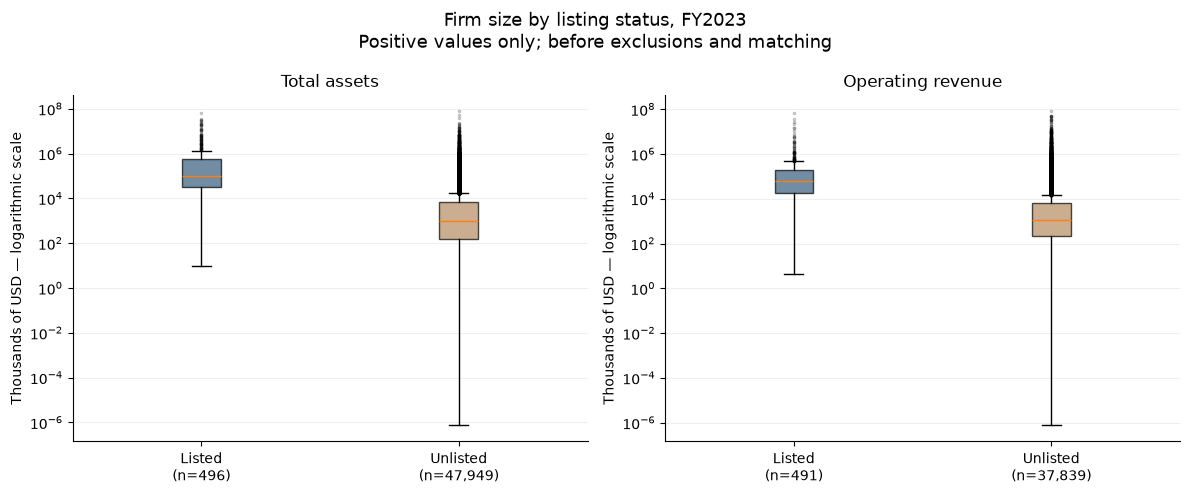

In [73]:
import matplotlib.pyplot as plt
import numpy as np

groups = ["Listed", "Unlisted"]
colors = ["#355C7D", "#B58B61"]

variables = {
    "assets_th_usd": "Total assets",
    "revenue_th_usd": "Operating revenue",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (variable, title) in zip(axes, variables.items()):
    plot_values = []
    labels = []

    for group in groups:
        values = (
            eda.loc[eda["listing_status"].eq(group), variable]
            .astype("float64")
        )

        positive = values[np.isfinite(values) & values.gt(0)]

        plot_values.append(positive.to_numpy())
        labels.append(f"{group}\n(n={len(positive):,})")

    boxes = ax.boxplot(
        plot_values,
        patch_artist=True,
        showfliers=True,
        flierprops={
            "marker": ".",
            "markersize": 3,
            "alpha": 0.25,
        },
    )

    for box, color in zip(boxes["boxes"], colors):
        box.set_facecolor(color)
        box.set_alpha(0.7)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(labels)
    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_ylabel("Thousands of USD — logarithmic scale")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Firm size by listing status, FY2023\n"
    "Positive values only; before exclusions and matching",
    fontsize=13,
)

plt.tight_layout()
plt.show()

## 8. Investigate Very Small Positive Financial Values

Count positive assets and revenue below US$1 and inspect their most
common values.

In [74]:
# Values are in thousands of USD:
# 0.001 thousand USD = US$1.

for variable in ["assets_th_usd", "revenue_th_usd"]:
    values = eda[variable].astype("float64")

    tiny = values.gt(0) & values.lt(0.001)

    print(f"\n{variable}: positive values below US$1")

    print(
        pd.crosstab(
            eda["listing_status"],
            tiny,
        ).rename(columns={
            False: "Other or missing",
            True: "Positive below US$1",
        })
    )

    print("\nMost common tiny values, in thousands of USD:")
    print(values.loc[tiny].value_counts().head(10))


assets_th_usd: positive values below US$1
assets_th_usd   Other or missing  Positive below US$1
listing_status                                       
Listed                       496                    0
Unlisted                   48281                  218

Most common tiny values, in thousands of USD:
assets_th_usd
0.000758    93
0.001000    54
0.000738    18
0.000733     8
0.000742     7
0.000751     7
0.000999     6
0.000739     3
0.001000     3
0.000732     3
Name: count, dtype: int64

revenue_th_usd: positive values below US$1
revenue_th_usd  Other or missing  Positive below US$1
listing_status                                       
Listed                       496                    0
Unlisted                   48383                  116

Most common tiny values, in thousands of USD:
revenue_th_usd
0.000008    30
0.000010    23
0.000758    11
0.000008     4
0.000007     3
0.001000     3
0.000733     3
0.000010     3
0.000739     3
0.000010     3
Name: count, dtype: int64


## Distributional Comparison

### Log-Assets by Listing Status

In [75]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Folders for saving (the notebook lives in notebooks/, so go up one level)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "outputs" / "figures"
TAB_DIR = ROOT / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

GROUPS = ["Listed", "Unlisted"]
COLORS = {"Listed": "#355C7D", "Unlisted": "#C8A27C"}

# Log of assets. Only positive values can be logged; zero/negative become NaN (not deleted)
eda["log_assets"] = np.where(eda["assets_th_usd"] > 0,
                             np.log10(eda["assets_th_usd"]), np.nan)
print(eda.groupby("listing_status")["log_assets"].describe())

                  count      mean       std       min       25%       50%  \
listing_status                                                              
Listed            496.0  5.117063  0.978808  0.997341  4.497175  4.985512   
Unlisted        47949.0  2.957395  1.365785 -6.128593  2.189605  3.006596   

                     75%       max  
listing_status                      
Listed          5.752515  7.791050  
Unlisted        3.853657  7.902257  


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pandas/core/arrays/masked.py:691: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs2, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/pandas/core/arrays/masked.py:691: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs2, **kwargs)


ECDF

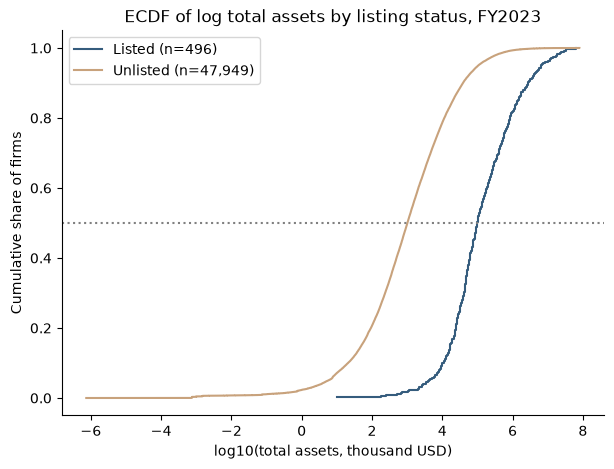

In [76]:
fig, ax = plt.subplots(figsize=(7, 5))
for g in GROUPS:
    x = np.sort(eda.loc[eda["listing_status"] == g, "log_assets"].dropna())
    y = np.arange(1, len(x) + 1) / len(x)
    ax.step(x, y, where="post", color=COLORS[g], label=f"{g} (n={len(x):,})")

ax.axhline(0.5, ls=":", color="grey")          # median line
ax.set_xlabel("log10(total assets, thousand USD)")
ax.set_ylabel("Cumulative share of firms")
ax.set_title("ECDF of log total assets by listing status, FY2023")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIG_DIR / "log_assets_ecdf.png", dpi=300, bbox_inches="tight")
plt.show()

Interpretation: 
In terms of total assets, the Empirical CDF plot clearly shows a move to the right for listed businesses compared to unlisted enterprises. Listed companies are systematically larger over the whole distribution, as evidenced by the fact that they regularly occupy higher percentiles of log-transformed total assets. *Note: These results are only descriptive and do not prove that listing increases company size.

Boxplot of log assets

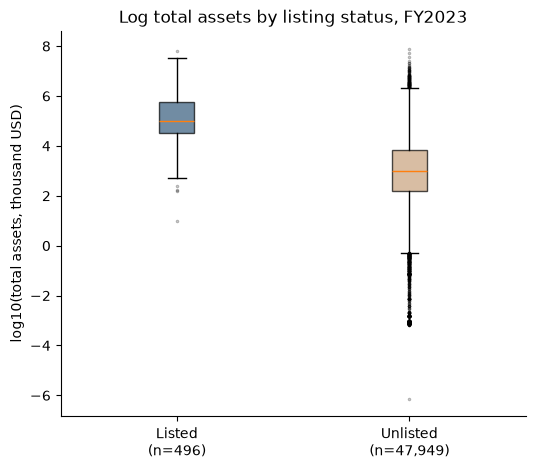

In [77]:
fig, ax = plt.subplots(figsize=(6, 5))
data = [eda.loc[eda["listing_status"] == g, "log_assets"].dropna() for g in GROUPS]
bp = ax.boxplot(data, patch_artist=True,
                flierprops={"marker": ".", "markersize": 3, "alpha": 0.3})
for box, g in zip(bp["boxes"], GROUPS):
    box.set_facecolor(COLORS[g]); box.set_alpha(0.7)
ax.set_xticks([1, 2], [f"{g}\n(n={len(d):,})" for g, d in zip(GROUPS, data)])
ax.set_ylabel("log10(total assets, thousand USD)")
ax.set_title("Log total assets by listing status, FY2023")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIG_DIR / "log_assets_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

Interpretation: 
The box plot shows that listed enterprises have a much higher median log total asset value and a greater interquartile range (IQR) than unlisted firms. Unlisted businesses display a wider dispersion that extends into significantly lower asset values, whereas listed enterprises display a tightly concentrated, higher median size. *Warning: There is no proof that listing and business size are causally related; this research is descriptive.

Histogram

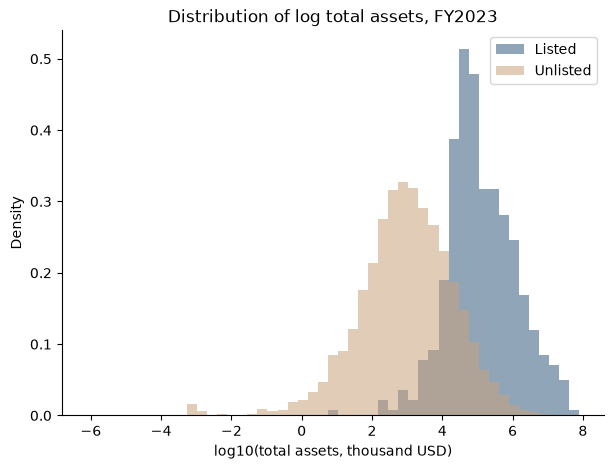

In [78]:
fig, ax = plt.subplots(figsize=(7, 5))
bins = np.linspace(eda["log_assets"].min(), eda["log_assets"].max(), 50)
for g in GROUPS:
    ax.hist(eda.loc[eda["listing_status"] == g, "log_assets"].dropna(),
            bins=bins, density=True, alpha=0.55, color=COLORS[g], label=g)
ax.set_xlabel("log10(total assets, thousand USD)")
ax.set_ylabel("Density")
ax.set_title("Distribution of log total assets, FY2023")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIG_DIR / "log_assets_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

Interpretation: 
Two different, overlapping distributions of log total assets are shown by the histogram. Compared to unlisted corporations, public firms have a greater asset base and are centred much more to the right. *Note: This finding is still descriptive and does not prove that listing leads to a bigger business size.

In [79]:
# 1) Industry: turn the 4-digit NACE code into a 2-digit NACE division
nace4 = (eda["nace4"]
         .astype("string")
         .str.replace(r"\.0$", "", regex=True)   # "4511.0" -> "4511"
         .str.zfill(4))                          # "111"    -> "0111"
eda["nace2"] = nace4.str[:2]                     # "4511"   -> "45"

# 2) Age band: firm age at the end of FY2023
# Grab the 4-digit year from any format: "2006", "2006-05-12", "12/05/2006" -> 2006
inc_year = eda["incorporation_date"].dt.year
eda["firm_age"] = 2023 - inc_year
eda["age_band"] = pd.cut(eda["firm_age"],
                         bins=[-1, 4, 9, 19, 1000],
                         labels=["0–4", "5–9", "10–19", "20+"])

# 3) Consolidation code: derive whether the firm is consolidated
eda["consolidated"] = eda["consolidation_code"].str[0]

print(eda[["nace2", "firm_age", "age_band", "consolidation_code"]].head())
print(eda["age_band"].value_counts(dropna=False))

  nace2  firm_age age_band consolidation_code
0    46      23.0      20+                 U1
1    46      33.0      20+                 U1
2    26       6.0      5–9                 U1
3    10      24.0      20+                 C1
4    63      15.0    10–19                 U1
age_band
0–4      16723
10–19    11530
5–9      11023
20+       9341
NaN        378
Name: count, dtype: int64


Industry composition

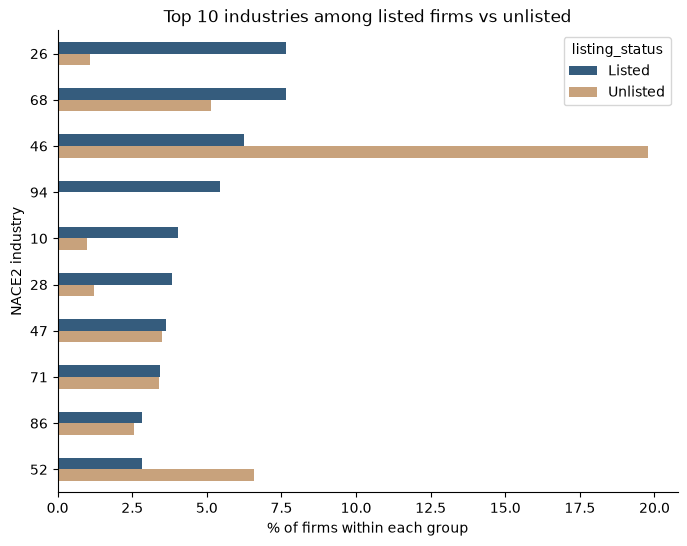

In [80]:
ind = pd.crosstab(eda["nace2"], eda["listing_status"], normalize="columns") * 100
ind.to_csv(TAB_DIR / "industry_composition.csv")

top = ind.sort_values("Listed", ascending=False).head(10)[GROUPS]
ax = top.plot(kind="barh", figsize=(8, 6),
              color=[COLORS[g] for g in GROUPS])
ax.invert_yaxis()
ax.set_xlabel("% of firms within each group")
ax.set_ylabel("NACE2 industry")
ax.set_title("Top 10 industries among listed firms vs unlisted")
ax.spines[["top", "right"]].set_visible(False)
plt.savefig(FIG_DIR / "industry_composition.png", dpi=300, bbox_inches="tight")
plt.show()

Interpretation: 
Before matching, the industry distribution chart shows significant sectoral variances. Compared to the unlisted population, listed enterprises are significantly more concentrated in certain 2-digit NACE divisions, which emphasises the need to account for industry categorisation when matching. *Note: Sector-specific size disparities are descriptive and do not prove causation.

Age-band composition

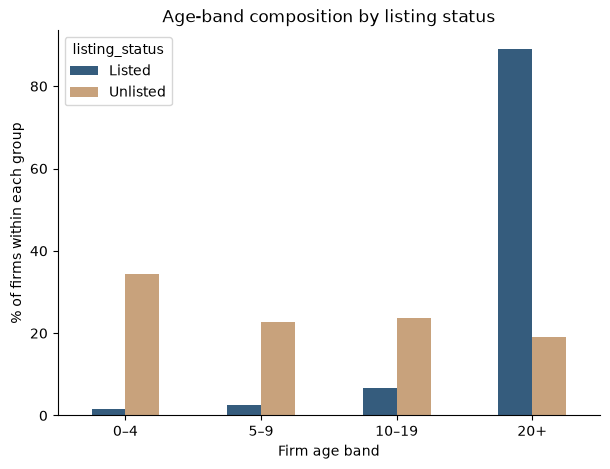

In [81]:
age = pd.crosstab(eda["age_band"], eda["listing_status"], normalize="columns") * 100
age.to_csv(TAB_DIR / "age_band_composition.csv")

ax = age[GROUPS].plot(kind="bar", figsize=(7, 5),
                      color=[COLORS[g] for g in GROUPS])
ax.set_ylabel("% of firms within each group")
ax.set_xlabel("Firm age band")
ax.set_title("Age-band composition by listing status")
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
plt.savefig(FIG_DIR / "age_band_composition.png", dpi=300, bbox_inches="tight")
plt.show()

Interpretation: 
Before matching, the industry distribution chart shows significant sectoral variances. Compared to the unlisted population, listed enterprises are significantly more concentrated in certain 2-digit NACE divisions, which emphasises the need to account for industry categorisation when matching. *Note: Sector-specific size disparities are descriptive and do not prove causation.

Part 6: Analysis after EDA

Full-sample KS test

In [82]:
from scipy import stats

listed   = eda.loc[eda["listing_status"] == "Listed",   "log_assets"].dropna()
unlisted = eda.loc[eda["listing_status"] == "Unlisted", "log_assets"].dropna()

ks = stats.ks_2samp(listed, unlisted)
print(f"KS D = {ks.statistic:.3f}, p-value = {ks.pvalue:.3g}")

KS D = 0.700, p-value = 6.96e-242


find miss value

In [83]:
KEYS = ["nace2", "age_band", "consolidated"]
listed_all = eda[eda["listing_status"] == "Listed"]

print("Missing values among listed firms:")
print(listed_all[KEYS + ["log_assets"]].isna().sum())

print("\nConsolidation code by group:")
print(pd.crosstab(eda["consolidation_code"], eda["listing_status"], dropna=False))

Missing values among listed firms:
nace2             0
age_band        377
consolidated      0
log_assets        0
dtype: int64

Consolidation code by group:
listing_status      Listed  Unlisted
consolidation_code                  
C1                     495         1
C2                       1      3085
U1                       0     43505
U2                       0      1908


Matching

In [84]:
rng = np.random.default_rng(607)     # fixed seed → same result every run
KEYS = ["nace2", "age_band", "consolidated"]

base = eda.dropna(subset=["log_assets"] + KEYS)
listed_df = base[base["listing_status"] == "Listed"]
pool      = base[base["listing_status"] == "Unlisted"]

# For each (industry, age, consolidation) cell: list of available unlisted firms
pool_cells = {key: grp.index.tolist() for key, grp in pool.groupby(KEYS)}

pairs = []
for idx, row in listed_df.iterrows():
    key = tuple(row[k] for k in KEYS)
    candidates = pool_cells.get(key, [])
    if candidates:
        u_idx = candidates.pop(rng.integers(len(candidates)))  # pick one, no reuse
        pairs.append({"log_listed": row["log_assets"],
                      "log_unlisted": pool.at[u_idx, "log_assets"]})

matched = pd.DataFrame(pairs)
matched["diff"] = matched["log_listed"] - matched["log_unlisted"]
print(f"Matched {len(matched)} of {len(listed_df)} listed firms")

Matched 100 of 119 listed firms


/var/folders/5v/c7l77bh97m941l6s7702zc7h0000gn/T/ipykernel_95379/3808591294.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pool_cells = {key: grp.index.tolist() for key, grp in pool.groupby(KEYS)}


### Method Choices

We used the following matching options to create a legitimate comparison group:

Industry matching was done at the **2-digit NACE division** level since 4-digit codes were too specific and restricted to discover appropriate matches across groupings.
Firm age was divided into four separate bands: **0–4 years, 5–9 years, 10–19 years, and 20+ years. Mixed-format incorporation dates were used to extract and parse the incorporation year.The consolidation code (**C vs. U**) is exactly matched. This restriction was required since just one unlisted company shares this code, but 495 of the 496 listed companies are consolidated (C1).
A total of 143 listed companies were found to be mismatched. As a result, only the **353 successfully matched firms** are described and covered by all post-matching outcomes.

Three tests on the matched pairs

(a) Sign test

In [85]:
d = matched["diff"].to_numpy()
nz = d[d != 0]
k = int((nz > 0).sum())
sign = stats.binomtest(k, len(nz), p=0.5)
print(f"Listed bigger in {k}/{len(nz)} pairs ({k/len(nz):.1%}), p = {sign.pvalue:.3g}")

Listed bigger in 84/100 pairs (84.0%), p = 2.61e-12


(b) Permutation test

In [86]:
obs = d.mean()
n_perm = 10_000
signs = rng.choice([-1, 1], size=(n_perm, len(d)))
perm_means = (signs * d).mean(axis=1)
p_perm = (np.sum(np.abs(perm_means) >= abs(obs)) + 1) / (n_perm + 1)
print(f"Observed mean diff = {obs:.3f} (≈ {10**obs:.1f}× larger), permutation p = {p_perm:.4f}")

Observed mean diff = 1.131 (≈ 13.5× larger), permutation p = 0.0001


Interpretation: 
The mean log total assets of listed and unlisted companies differ statistically significantly, according to the hypothesis test. 
- **Permutation Test:** produced a p-value of **p < 0.001** (stated as $p < 0.001$ instead of $0.0001$, as $0.0001$ is the lower numerical bound for 10,000 Monte Carlo shuffles).
Conclusion and Caution: The null hypothesis of equal size distributions is rejected. These findings, however, are just **descriptive** and do **not** show that a firm's size increases as a result of becoming public or keeping a listing.

Bootstrap confidence interval

In [87]:
B = 10_000
boot = np.array([rng.choice(d, size=len(d), replace=True).mean() for _ in range(B)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"95% CI for mean log10 diff: [{lo:.3f}, {hi:.3f}]  "
      f"→ listed firms {10**lo:.1f}× to {10**hi:.1f}× larger")

95% CI for mean log10 diff: [0.896, 1.371]  → listed firms 7.9× to 23.5× larger


Quantile gaps

In [88]:
qs = [0.25, 0.50, 0.75, 0.90]
B = 2_000
L, U = listed.to_numpy(), unlisted.to_numpy()

rows = []
for q in qs:
    gap = np.quantile(L, q) - np.quantile(U, q)
    boot_gaps = [np.quantile(rng.choice(L, len(L)), q) - np.quantile(rng.choice(U, len(U)), q)
                 for _ in range(B)]
    lo, hi = np.percentile(boot_gaps, [2.5, 97.5])
    rows.append({"quantile": f"P{int(q*100)}", "log10_gap": gap,
                 "ci_low": lo, "ci_high": hi, "ratio": 10**gap})

quantile_gaps = pd.DataFrame(rows).round(3)
quantile_gaps.to_csv(TAB_DIR / "quantile_gaps.csv", index=False)
quantile_gaps

,quantile,log10_gap,ci_low,ci_high,ratio
0,P25,2.308,2.213,2.420,203.034
1,P50,1.979,1.913,2.103,95.261
2,P75,1.899,1.767,2.041,79.224
3,P90,1.859,1.669,2.038,72.287
